In [1]:
# Part 1: Understanding Product Categories
# Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

# Frequency Tables:

# Generate a frequency table for the product category.
# Which are the top 5 most listed product categories?
# Visualizations:

# Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
# For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [7]:
url = 'amz_uk_price_prediction_dataset.csv'
df = pd.read_csv(url)

In [11]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [15]:
category_counts = df['category'].value_counts()
category_counts


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [17]:
top_5_categories = category_counts.head(5)
top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

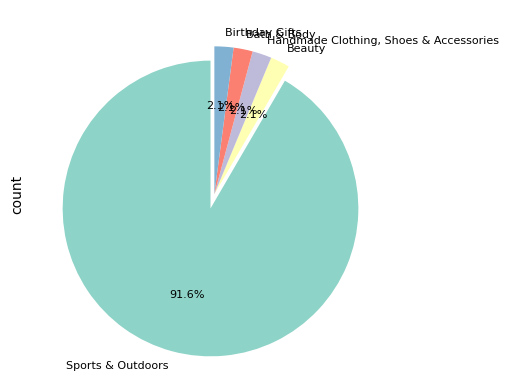

In [43]:
explode = [0.1 if value == top_5_categories.max() else 0 for value in top_5_categories]
top_5_categories.plot.pie(autopct='%1.1f%%',startangle=90, colors=sns.color_palette("Set3"),explode=explode, fontsize=8);
plt.show()

In [45]:
# Part 2: Delving into Product Pricing
# Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

# Measures of Centrality:

# Calculate the mean, median, and mode for the price of products.
# What's the average price point of products listed? How does this compare with the most common price point (mode)?
# Measures of Dispersion:

# Determine the variance, standard deviation, range, and interquartile range for product price.
# How varied are the product prices? Are there any indicators of a significant spread in prices?
# Visualizations:

# Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
# Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.


In [63]:
mean_price = round(df['price'].mean(),2)
median_price = round(df['price'].median(),2)
mode_price = round(df['price'].mode()[0],2)

print(f"Mean:{mean_price}")
print(f"Median:{median_price}")
print(f"Mode:{mode_price}")

Mean:89.24
Median:19.09
Mode:9.99


In [65]:
# Mean is much higher than the mode, it suggests that there are some higher-priced products pulling up the average price.

In [69]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()

price_range = df['price'].max() - df['price'].min()

IQR_price = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"Variance in Price: {variance_price}")
print(f"Standard Deviation in Price: {std_dev_price}")
print(f"Price Range: {price_range}")
print(f"Interquartile Range (IQR): {IQR_price}")

Variance in Price: 119445.4853225653
Standard Deviation in Price: 345.6088617535223
Price Range: 100000.0
Interquartile Range (IQR): 36.0


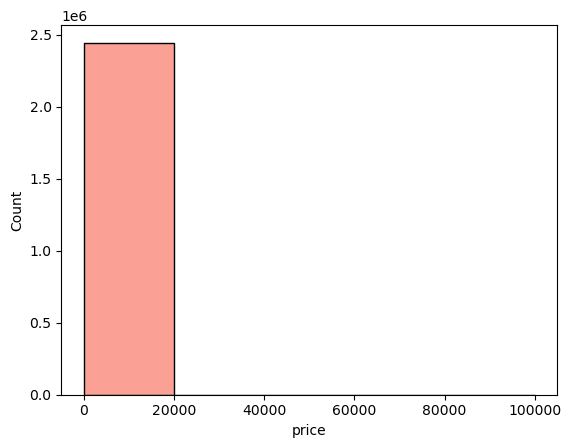

In [86]:
sns.histplot(df['price'], bins=5, color='salmon')
plt.show()

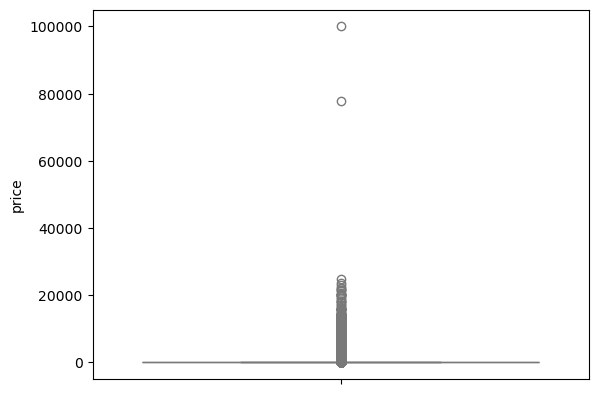

In [89]:
sns.boxplot(data = df['price'], color="lightblue")
plt.show()

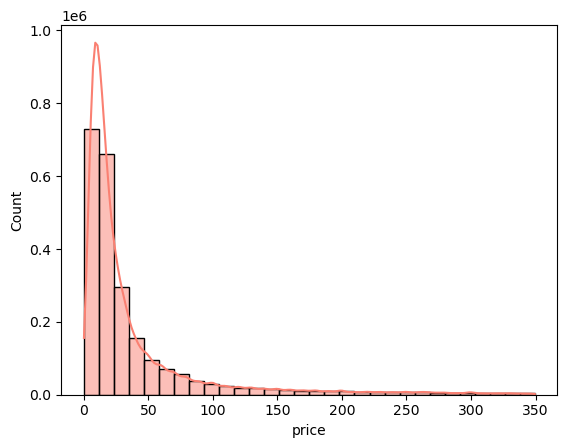

In [94]:
price_threshold = df['price'].quantile(0.95)
filtered_df = df[df['price'] <= price_threshold]

sns.histplot(filtered_df['price'], kde=True, bins=30, color='salmon')
plt.show()

In [96]:
# Removes extreme outliers: Any price above the 95th percentile is removed.
# More readable histogram: Focuses on common price ranges.

In [98]:
# Part 3: Unpacking Product Ratings
# Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

# Measures of Centrality:

# Calculate the mean, median, and mode for the rating of products.
# How do customers generally rate products? Is there a common trend?
# Measures of Dispersion:

# Determine the variance, standard deviation, and interquartile range for product rating.
# Are the ratings consistent, or is there a wide variation in customer feedback?
# Shape of the Distribution:

# Calculate the skewness and kurtosis for the rating column.
# Are the ratings normally distributed, or do they lean towards higher or lower values?
# Visualizations:

# Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [102]:
mean_rating = round(df['stars'].mean(), 2)
median_rating = round(df['stars'].median(), 2)
mode_rating = round(df['stars'].mode()[0], 2)

print(f"Mean Rating: {mean_rating}")
print(f"Median Rating: {median_rating}")
print(f"Mode Rating: {mode_rating}")

Mean Rating: 2.15
Median Rating: 0.0
Mode Rating: 0.0


In [106]:
variance_rating = round(df['stars'].var(), 2)
std_dev_rating = round(df['stars'].std(), 2)
IQR_rating = round(df['stars'].quantile(0.75) - df['stars'].quantile(0.25), 2)

print(f"Variance in Rating: {variance_rating}")
print(f"Standard Deviation in Rating: {std_dev_rating}")
print(f"Interquartile Range (IQR): {IQR_rating}")

Variance in Rating: 4.82
Standard Deviation in Rating: 2.19
Interquartile Range (IQR): 4.4


In [111]:
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(0.08120735761080985, -1.9260061280432985)

In [114]:
# Since skewness is close to 0, the ratings are nearly symmetric.
# This means there isn’t a strong tendency for ratings to be higher or lower—they are relatively balanced.

In [116]:
# A negative kurtosis suggests a flatter distribution than a normal curve.
# This means the ratings are spread out, and there aren’t extreme peaks at any one rating

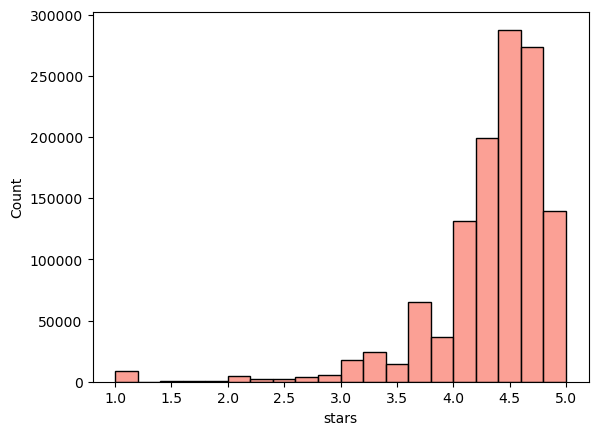

In [141]:
filtered_df = df[df['reviews']>0]
sns.histplot(filtered_df['stars'], bins=20, color='salmon')
plt.show()

In [143]:
# stars with 4.5 are the most common

In [145]:
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64